# Homework 6: Flow Through a Pipe with Obstacles
EPS 109. Obstacle: **#7, two horizontal lines** (last digit of student ID = 7).

This code is adapted from the Lab 6 DLA code. There is no aggregation here: the matrix `A` (walls and obstacles) never changes. Each particle starts at the right end of the pipe and random-walks with a drift to the left. It **succeeds** if it reaches the left end (column `x = 0`). It **fails** if it gets stuck on a wall or an obstacle. As in the DLA code, a particle gets stuck as soon as one of its four neighbors (or its own site) is filled.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML
%matplotlib inline

## (1) Set up the pipe
`maxX = 200`, `maxY = 40`. The bottom row (`y = 0`) and top row (`y = maxY-1`) are filled with 1.

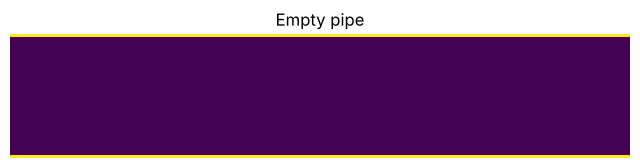

In [2]:
maxX = 200
maxY = 40

def make_pipe(maxX=200, maxY=40):
    A = np.zeros((maxX, maxY))
    A[:, 0] = 1          # bottom wall
    A[:, maxY-1] = 1     # top wall
    return A

def show_pipe(A, title=''):
    plt.figure(figsize=(8, 8*A.shape[1]/A.shape[0] + 0.4))
    plt.imshow(A.T, origin='lower', interpolation='nearest')
    plt.title(title); plt.axis('off'); plt.show()

A0 = make_pipe(maxX, maxY)
show_pipe(A0, 'Empty pipe')

## (2)–(4) Random walk with a flow to the left
* (2) Every particle starts in the middle of the pipe at the very right: `x = maxX-1`, `y = maxY//2`. `yBuffer` is no longer used.
* (3) Step probabilities: left 50%, right 10%, up 20%, down 20%. A step out through the right end is blocked. The particle stays where it is and keeps walking.
* (6) Every 10 steps, the particle's position is added to frame `step//10 - 1` of `B`, for the first `nFrames = 50` frames (500 steps).

In [3]:
nFrames = 50
stepsPerFrame = 10

def walk(Al, maxX, maxY, B=None):
    """Random walk of one particle. Al = A as nested lists of bools (faster than numpy indexing).
    Returns True if the particle reaches the left end, False if it gets stuck."""
    x = maxX - 1
    y = maxY // 2
    step = 0
    while True:
        r = np.random.random()
        if r < 0.5:                 # left  (50%)
            x = x - 1
        elif r < 0.6:               # right (10%), blocked at the right end
            if x < maxX - 1:
                x = x + 1
        elif r < 0.8:               # up    (20%)
            y = y + 1
        else:                       # down  (20%)
            y = y - 1
        step += 1

        # stuck? (site itself or any of its four neighbors is filled)
        xm = x - 1 if x > 0 else x
        xp = x + 1 if x < maxX - 1 else x
        if Al[x][y] or Al[xm][y] or Al[xp][y] or Al[x][y+1] or Al[x][y-1]:
            return False

        # record position for the animation
        if B is not None and step % stepsPerFrame == 0:
            iFrame = step // stepsPerFrame - 1
            if iFrame < B.shape[0]:
                B[iFrame, x, y] += 1

        if x == 0:                  # reached the left end
            return True

def run(A, N, B=None, report=1000, verbose=True):
    """Send N particles through pipe A. Returns the number of successes and the running estimates."""
    maxX, maxY = A.shape
    Al = (A == 1).tolist()
    nSuccess = 0
    history = []
    for i in range(1, N+1):
        if walk(Al, maxX, maxY, B):
            nSuccess += 1
        if i % report == 0:
            P = nSuccess / i
            history.append((i, P))
            if verbose:
                print(f'N = {i:6d}   successes = {nSuccess:6d}   P = {P:.4f}')
    return nSuccess, history

### (4) First test with 1000 particles, then 20,000

In [4]:
np.random.seed(0)
n, _ = run(A0, 1000, verbose=False)
print(f'N = 1000:   P_success = {n/1000:.4f}')

np.random.seed(1)
n, _ = run(A0, 20000, verbose=False)
print(f'N = 20000:  P_success = {n/20000:.4f}')

N = 1000:   P_success = 0.6210


N = 20000:  P_success = 0.6229


## (5)–(6) Visualizing the diffusion
The display function from the assignment shows `log(B)` with the walls and obstacles drawn at the maximum value. It works on a copy of `B`, so the recorded data isn't changed.

In [5]:
# This function displays the contents of matrices A and B over our simulation cell
# A[ix,iy]=1 indicates boundaries and the obstacles. This matrix should not change with time.
# B[ix,iy]>0 indicates how many particles were present at this location at one time.
def frame_image(A, B):
    B = B.copy()
    maxX = A.shape[0]
    maxY = A.shape[1]
    m2 = np.max(B)
    B[A[:,:]==1] = m2                   # where A[ix,iy]==1, set all pixels of B to the maximum of B
    if (m2 > 0):
        m1 = np.min(B[B[:,:]>0])
        if (m1 == m2): m1 = m2/2
        B[B[:,:]==0] = m1*(m1/m2)**(1/10)  # where B[ix,iy]==0, set to below the nonzero minimum of B
    D = np.zeros((maxY, maxX))
    for iy in range(0, maxY):
        D[maxY-1-iy, :] = np.log(B[:, iy])  # log scale to show a wide range
    return D

def display(A, B):
    plt.imshow(frame_image(A, B))
    plt.axis('off')
    plt.show()
    plt.draw()
    plt.pause(0.1)   # 0.01 on a Mac and 0.1 on PC

# To play it in a pop-up window as in the assignment (with %matplotlib osx), use:
# while(True):
#     for i in range(nFrames):
#         display(A, B[i,:,:])

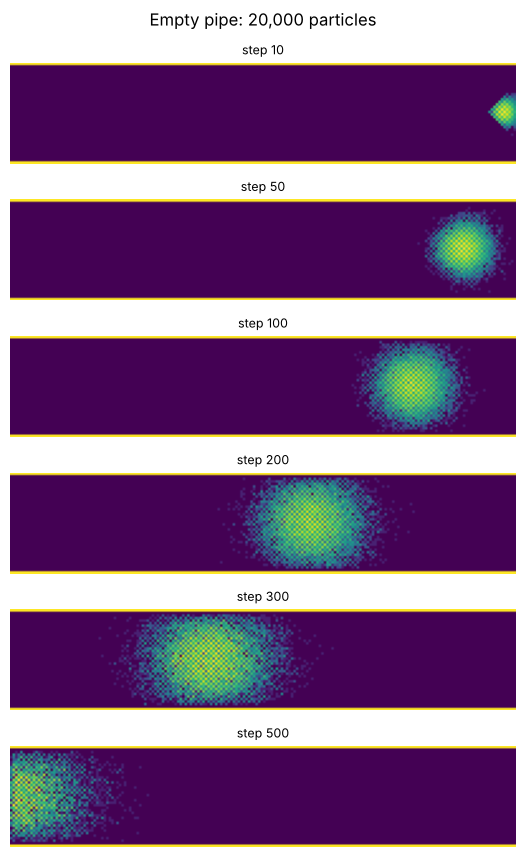

In [6]:
def frames_grid(A, B, title, frames=(0, 4, 9, 19, 29, 49)):
    fig, axs = plt.subplots(len(frames), 1, figsize=(8, 1.45*len(frames)))
    for ax, i in zip(axs, frames):
        ax.imshow(frame_image(A, B[i]))
        ax.set_title(f'step {(i+1)*stepsPerFrame}', fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

def animate(A, B, fname=None):
    fig, ax = plt.subplots(figsize=(8, 2))
    im = ax.imshow(frame_image(A, B[0])); ax.axis('off')
    title = ax.set_title('')
    def update(i):
        D = frame_image(A, B[i])
        im.set_data(D); im.set_clim(D.min(), D.max())
        title.set_text(f'step {(i+1)*stepsPerFrame}')
        return im, title
    ani = animation.FuncAnimation(fig, update, frames=B.shape[0], interval=100)
    if fname:
        ani.save(fname, writer='pillow', fps=10)
    plt.close(fig)
    return HTML(ani.to_jshtml())

np.random.seed(2)
B0 = np.zeros((nFrames, maxX, maxY))
run(A0, 20000, B=B0, verbose=False)
frames_grid(A0, B0, 'Empty pipe: 20,000 particles')

In [7]:
animate(A0, B0, 'flow_empty.gif')

The particles start as one bright point at the right. They drift left at about 0.4 sites per step and spread out vertically because of diffusion. Once the cloud is as wide as the pipe, particles touching the walls get stuck and drop out. That's why the cloud gets dimmer before it reaches the left end at about step 500.

## (7) Success probability for the empty pipe
The statistical error of a success fraction is $\sigma_P = \sqrt{P(1-P)/N}$. The code adds particles 1000 at a time and prints the running value. It stops once $\sigma_P \le 0.002$ (0.2%), after at least 20,000 particles.

In [8]:
def estimate(A, tol=0.002, Nmin=20000, Nmax=200000, batch=1000, seed=3):
    np.random.seed(seed)
    maxX, maxY = A.shape
    Al = (A == 1).tolist()
    nSuccess = 0
    N = 0
    history = []
    while N < Nmax:
        for _ in range(batch):
            if walk(Al, maxX, maxY):
                nSuccess += 1
        N += batch
        P = nSuccess / N
        err = np.sqrt(P*(1-P)/N)
        history.append((N, P))
        print(f'N = {N:6d}   P = {P:.4f} +- {err:.4f}')
        if N >= Nmin and err <= tol:
            break
    print(f'\n==> P_success = {P:.4f} +- {err:.4f}  (N = {N})')
    return P, err, np.array(history)

P0, err0, hist0 = estimate(A0)

N =   1000   P = 0.6080 +- 0.0154


N =   2000   P = 0.6085 +- 0.0109


N =   3000   P = 0.6110 +- 0.0089


N =   4000   P = 0.6082 +- 0.0077


N =   5000   P = 0.6072 +- 0.0069


N =   6000   P = 0.6065 +- 0.0063


... (49 outputs left out)

N =  56000   P = 0.6211 +- 0.0020


N =  57000   P = 0.6213 +- 0.0020


N =  58000   P = 0.6211 +- 0.0020


N =  59000   P = 0.6210 +- 0.0020

==> P_success = 0.6210 +- 0.0020  (N = 59000)


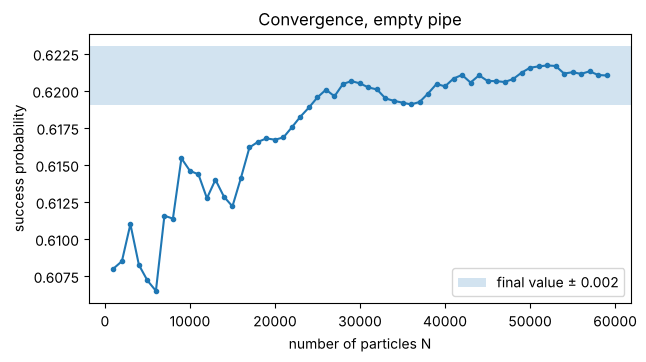

In [9]:
plt.figure(figsize=(7,3.5))
plt.plot(hist0[:,0], hist0[:,1], '.-')
plt.axhspan(P0-0.002, P0+0.002, alpha=0.2, label='final value ± 0.002')
plt.xlabel('number of particles N'); plt.ylabel('success probability')
plt.title('Convergence, empty pipe'); plt.legend(); plt.show()

### Answer (7)
**Final value, empty pipe: P_success = 0.621 ± 0.002** (N = 59,000 particles).

The running value moves around by about 1% for the first 10,000 particles. It doesn't settle within ±0.002 until about 50,000 particles. That matches $\sigma_P=\sqrt{P(1-P)/N}$: for P ≈ 0.62, you need N ≈ 0.24/0.002² ≈ 59,000.

Why about 62%: the drift to the left is 0.5 − 0.1 = 0.4 sites per step, so crossing 200 sites takes about 500 steps. Vertically, the particle takes ±1 steps 40% of the time, so its spread grows as $\sigma_y \approx \sqrt{0.4\,t}$, which is about 14 sites after 500 steps. A particle is lost when it reaches row 1 or row 38, about 19 sites from where it starts. So a sizable fraction of particles reaches a wall before getting through.

## (8) Obstacle #7: two horizontal lines
Two horizontal lines, 1 pixel thick and 100 sites long (`x = 50 … 149`, centered in the pipe), at `y = 13` and `y = 26`. That splits the middle part of the pipe into three channels of about equal width, as in the sketch.

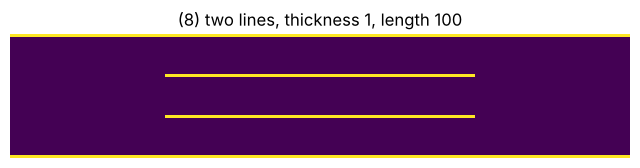

N =   1000   P = 0.0140 +- 0.0037
N =   2000   P = 0.0120 +- 0.0024


N =   3000   P = 0.0130 +- 0.0021
N =   4000   P = 0.0147 +- 0.0019
N =   5000   P = 0.0132 +- 0.0016


N =   6000   P = 0.0133 +- 0.0015
N =   7000   P = 0.0127 +- 0.0013
N =   8000   P = 0.0126 +- 0.0012


N =   9000   P = 0.0126 +- 0.0012
N =  10000   P = 0.0124 +- 0.0011
N =  11000   P = 0.0124 +- 0.0011


N =  12000   P = 0.0123 +- 0.0010
N =  13000   P = 0.0118 +- 0.0009
N =  14000   P = 0.0121 +- 0.0009


N =  15000   P = 0.0118 +- 0.0009
N =  16000   P = 0.0118 +- 0.0009
N =  17000   P = 0.0121 +- 0.0008


N =  18000   P = 0.0120 +- 0.0008
N =  19000   P = 0.0118 +- 0.0008


N =  20000   P = 0.0116 +- 0.0008

==> P_success = 0.0116 +- 0.0008  (N = 20000)


In [10]:
x0, x1 = 50, 150         # lines span x = 50 ... 149 (centered, length 100)
yLow, yHigh = 13, 26     # roughly 1/3 and 2/3 of the pipe height (symmetric about the center)

A8 = make_pipe(maxX, maxY)
A8[x0:x1, yLow]  = 1
A8[x0:x1, yHigh] = 1
show_pipe(A8, '(8) two lines, thickness 1, length 100')

P8, err8, _ = estimate(A8)

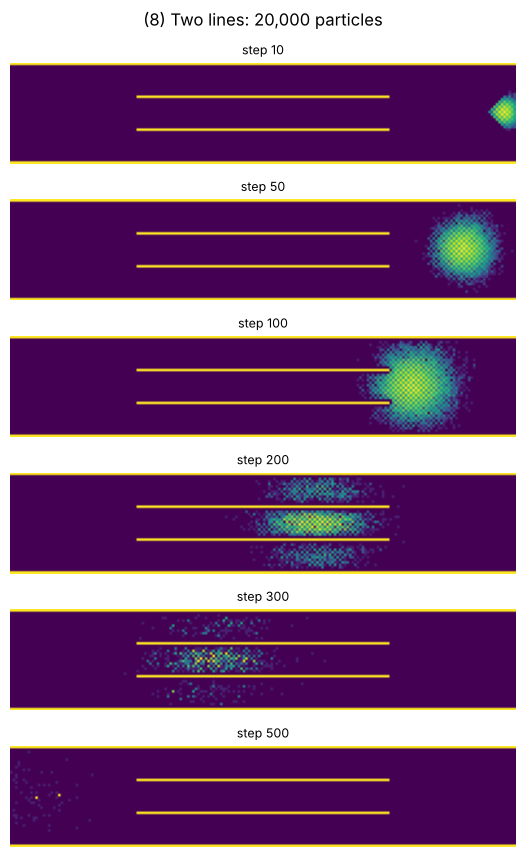

In [11]:
np.random.seed(4)
B8 = np.zeros((nFrames, maxX, maxY))
run(A8, 20000, B=B8, verbose=False)
frames_grid(A8, B8, '(8) Two lines: 20,000 particles')

In [12]:
animate(A8, B8, 'flow_two_lines.gif')

### Answer (8)
**Two lines (length 100, thickness 1): P_success = 0.0116 ± 0.0008.** That's about 50 times lower than the empty pipe.

The animation shows why. When the cloud reaches the lines (around step 100), many particles land directly on the line ends and stick. The rest are split into three channels that are only 12 rows wide. Because a particle sticks when it's next to a filled site, only 10 rows in each channel are safe. To get through, a particle has to travel 100 sites (about 250 steps) inside that narrow strip. Over 250 steps its vertical spread is $\sigma_y \approx \sqrt{0.4\cdot 250}\approx 10$ sites, which is much larger than the half-width of the strip (about 5 sites). Almost every particle touches a line or a wall along the way. The lines add a lot of sticky surface right where the particles are.

A rough estimate: in a strip with absorbing walls a distance $w$ apart, survival falls off like $\exp(-\pi^2 D t / w^2)$ with $D = 0.2$. With $w = 11$ and $t = 250$, that gives $e^{-4.1}\approx 0.017$. That's the same order as the measured value.

## (9) Lines twice as thick
Each line becomes 2 pixels thick. A 1-pixel line can't grow by one pixel symmetrically, so each line is thickened **toward the center of the pipe** (rows 13–14 and 25–26). That keeps the setup mirror-symmetric about the middle of the pipe.

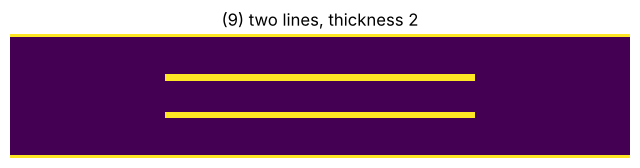

N =   1000   P = 0.0040 +- 0.0020
N =   2000   P = 0.0030 +- 0.0012
N =   3000   P = 0.0020 +- 0.0008


N =   4000   P = 0.0022 +- 0.0007
N =   5000   P = 0.0024 +- 0.0007
N =   6000   P = 0.0022 +- 0.0006


N =   7000   P = 0.0023 +- 0.0006
N =   8000   P = 0.0021 +- 0.0005
N =   9000   P = 0.0021 +- 0.0005


N =  10000   P = 0.0022 +- 0.0005
N =  11000   P = 0.0021 +- 0.0004
N =  12000   P = 0.0022 +- 0.0004


N =  13000   P = 0.0021 +- 0.0004
N =  14000   P = 0.0021 +- 0.0004
N =  15000   P = 0.0025 +- 0.0004


N =  16000   P = 0.0024 +- 0.0004
N =  17000   P = 0.0024 +- 0.0004
N =  18000   P = 0.0025 +- 0.0004


N =  19000   P = 0.0025 +- 0.0004
N =  20000   P = 0.0026 +- 0.0004

==> P_success = 0.0026 +- 0.0004  (N = 20000)


In [13]:
A9 = make_pipe(maxX, maxY)
A9[x0:x1, yLow:yLow+2]    = 1     # rows 13, 14
A9[x0:x1, yHigh-1:yHigh+1] = 1    # rows 25, 26
show_pipe(A9, '(9) two lines, thickness 2')

P9, err9, _ = estimate(A9)

### Answer (9)
**Lines twice as thick: P_success = 0.0026 ± 0.0004.** That's about 4–5 times lower than in (8).

The particles start at the center (`y = 20`), so most of the survivors in (8) went through the **middle channel**. Thickening both lines toward the center shrinks the safe width of that channel from 10 rows to 8. The extra material at the line ends also catches a few more particles head-on.

The effect is large because survival in a channel depends **exponentially** on $t/w^2$. With the absorbing boundaries now at $w = 9$ instead of 11, the estimate becomes $\exp(-\pi^2\cdot0.2\cdot250/81)\approx e^{-6.1}\approx 0.002$. That's several times lower, which matches the simulation. A small change in channel width gives a big change in transmission.

## (10) Lines half as long
Original 1-pixel lines, but only 50 sites long and re-centered (`x = 75 … 124`).

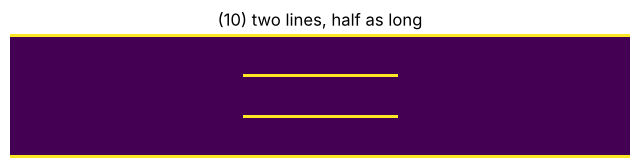

N =   1000   P = 0.0630 +- 0.0077
N =   2000   P = 0.0685 +- 0.0056


N =   3000   P = 0.0657 +- 0.0045
N =   4000   P = 0.0665 +- 0.0039


N =   5000   P = 0.0640 +- 0.0035
N =   6000   P = 0.0630 +- 0.0031


N =   7000   P = 0.0629 +- 0.0029
N =   8000   P = 0.0620 +- 0.0027


N =   9000   P = 0.0621 +- 0.0025
N =  10000   P = 0.0626 +- 0.0024


N =  11000   P = 0.0621 +- 0.0023
N =  12000   P = 0.0628 +- 0.0022


N =  13000   P = 0.0640 +- 0.0021
N =  14000   P = 0.0645 +- 0.0021


N =  15000   P = 0.0655 +- 0.0020
N =  16000   P = 0.0658 +- 0.0020


N =  17000   P = 0.0659 +- 0.0019
N =  18000   P = 0.0662 +- 0.0019


N =  19000   P = 0.0662 +- 0.0018
N =  20000   P = 0.0655 +- 0.0017

==> P_success = 0.0655 +- 0.0017  (N = 20000)


In [14]:
A10 = make_pipe(maxX, maxY)
A10[75:125, yLow]  = 1
A10[75:125, yHigh] = 1
show_pipe(A10, '(10) two lines, half as long')

P10, err10, _ = estimate(A10)

### Answer (10)
**Lines half as long (50 sites): P_success = 0.066 ± 0.002.** That's about 6 times *higher* than in (8), but still far below the empty pipe (0.62).

The channel width is the same as in (8), but particles only have to stay inside the narrow channels for about 125 steps instead of 250. The chance of surviving inside a channel drops roughly exponentially with the time spent there. So halving the length roughly takes the square root of the channel's transmission factor: $0.62\cdot\sqrt{0.0116/0.62}\approx 0.085$. That's close to the measured 0.066 (the line ends still catch particles directly).

**Summary:** the obstacles mainly hurt by forcing particles into narrow corridors. Transmission is very sensitive to the corridor width (question 9) and to its length (question 10).

In [15]:
print('Summary of success probabilities')
for name, P, e in [('(7)  empty pipe', P0, err0), ('(8)  two lines', P8, err8),
                   ('(9)  lines twice as thick', P9, err9), ('(10) lines half as long', P10, err10)]:
    print(f'{name:28s}  P = {P:.4f} +- {e:.4f}')

Summary of success probabilities
(7)  empty pipe               P = 0.6210 +- 0.0020
(8)  two lines                P = 0.0116 +- 0.0008
(9)  lines twice as thick     P = 0.0026 +- 0.0004
(10) lines half as long       P = 0.0655 +- 0.0017
